# 04 - RQ3: Do Claims Form Groups with Similar Flood Risk?

**DSC 411/511 Semester Project** · Venkat Repaka, Ritik Gaire

**RQ3:** Do claims form groups (clusters) with similar flood risk?

This is **clustering**: there is no target. We group claims by their **building facts** only (flood zone, foundation, floors,
occupancy, age, coverage, CRS class). We do **not** use damage or payment to make the groups. Afterwards we check if the groups
have a different **range of damage** (damage ratio), which tells us whether they are real risk profiles.

**Plan**
1. Prepare the data
2. How many clusters? (elbow and silhouette)
3. K-means and hierarchical clustering
4. What is in each cluster?
5. Do the clusters have different risk? (outcomes they never saw)
6. PCA: does a smaller version of the data give better clusters?
7. DBSCAN: a different kind of clustering
8. Our answer

## 1. Prepare the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')
SEED = 42

df = pd.read_parquet('data/claims_clean.parquet')
print('Claims:', f'{len(df):,}')
print('Foundation codes:', df['foundation'].value_counts().to_dict())

Claims: 276,570
Foundation codes: {'1': 153510, '0': 26164, '2': 24232, '3': 20258, '5': 19312, '4': 16722, '6': 16372}


**A problem we found:** old (legacy) policies did not record the foundation; they all have code `0`.
When we first clustered with them, one cluster was just "old policies", which is about the data system, not about flood risk.
So we leave out claims with foundation `0`.

Clustering is slow on 270,000 claims, so we use a **random sample of 20,000 claims**.

In [2]:
d = df[~df['foundation'].isin(['0', 'unknown'])].sample(20000, random_state=SEED).copy()
CATEGORY = ['zone', 'foundation', 'numberOfFloorsInTheInsuredBuilding', 'occupancy']
NUMBER = ['building_age', 'crsClassCode', 'totalBuildingInsuranceCoverage']
Xc = pd.get_dummies(d[CATEGORY + NUMBER], columns=CATEGORY, dtype=int)
Xs = StandardScaler().fit_transform(Xc)          # same scale for every column, so no column dominates the distance
print('Sample:', len(d), '   columns after one-hot encoding:', Xc.shape[1])

Sample: 20000    columns after one-hot encoding: 32


## 2. How many clusters?

We try k = 2 to 8. **Inertia** (elbow method) always goes down when k grows. **Silhouette** (-1 to 1) says how well each claim fits
its own cluster compared with the next one; higher is better. Our rule, chosen before looking: the k between 3 and 8 with the best silhouette
(2 groups would be too rough to be called risk profiles).

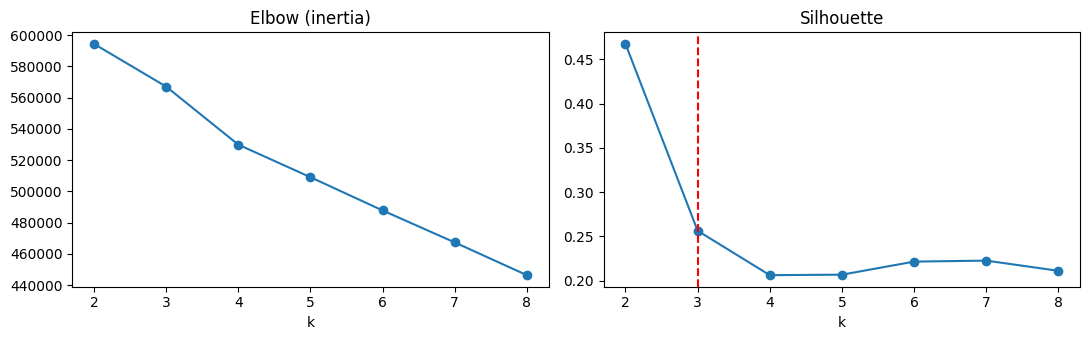

      inertia  silhouette
k                        
2  594453.538       0.467
3  567113.756       0.256
4  529929.679       0.206
5  509094.570       0.207
6  487800.628       0.221
7  467328.260       0.223
8  446353.405       0.211
Chosen k: 3


In [3]:
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xs)
    rows.append({'k': k, 'inertia': km.inertia_, 'silhouette': silhouette_score(Xs, km.labels_, sample_size=5000, random_state=SEED)})
ks = pd.DataFrame(rows).set_index('k')
K = int(ks.loc[3:, 'silhouette'].idxmax())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ks['inertia'].plot(ax=ax[0], marker='o', title='Elbow (inertia)')
ks['silhouette'].plot(ax=ax[1], marker='o', title='Silhouette'); ax[1].axvline(K, color='red', ls='--')
plt.tight_layout(); plt.show()
print(ks.round(3)); print('Chosen k:', K)

## 3. K-means and hierarchical clustering

Hierarchical clustering (Ward) needs a lot of memory, so we run it on 5,000 of the 20,000 claims and compare it with K-means on the
same claims. **ARI** (adjusted Rand index) says how much two clusterings agree: 1 = the same groups, 0 = no more than chance.

In [4]:
kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(Xs)
d['cluster'] = kmeans.labels_
sub = np.random.default_rng(SEED).choice(len(Xs), 5000, replace=False)
ward = AgglomerativeClustering(n_clusters=K, linkage='ward').fit(Xs[sub])
print(f'Silhouette K-means     : {silhouette_score(Xs[sub], kmeans.labels_[sub]):.3f}')
print(f'Silhouette hierarchical: {silhouette_score(Xs[sub], ward.labels_):.3f}')
print(f'Agreement (ARI)        : {adjusted_rand_score(kmeans.labels_[sub], ward.labels_):.3f}')
print(); print('Claims per K-means cluster:'); print(d['cluster'].value_counts().sort_index())

Silhouette K-means     : 0.262


Silhouette hierarchical: 0.259
Agreement (ARI)        : 0.220

Claims per K-means cluster:
cluster
0    16980
1     2529
2      491
Name: count, dtype: int64


**What we see.** The silhouette rule chose **k = 3**. The silhouette is low (0.26), which means the clusters overlap a lot.
Hierarchical clustering gives almost the same silhouette (0.26), but it agrees only a little with K-means (ARI 0.22), so the two
methods do not find the same groups. One K-means cluster has 16,980 of the 20,000 claims, which already looks too big.
(k = 2 had an even higher silhouette, 0.47, but our rule did not allow 2 groups.)

## 4. What is in each cluster?

In [5]:
FOUNDATION_NAMES = {'1': 'slab', '2': 'basement', '3': 'crawlspace', '4': 'elevated (4)', '5': 'elevated (5)', '6': 'elevated (6)'}
OCCUPANCY_NAMES = {'11.0': 'single family', '12.0': '2-4 units', '13.0': '5+ units', '14.0': 'mobile home', '15.0': 'condo building',
                   '16.0': 'unit in building', '17.0': 'non-res. mobile', '18.0': 'non-residential', '19.0': 'non-res. unit'}
most_common = lambda s: s.value_counts().index[0]
share_most_common = lambda s: s.value_counts(normalize=True).iloc[0]
profile = d.groupby('cluster').agg(claims=('id', 'size'), median_age=('building_age', 'median'),
                                   median_coverage=('totalBuildingInsuranceCoverage', 'median'),
                                   zone=('zone', most_common), foundation=('foundation', most_common),
                                   foundation_share=('foundation', share_most_common),
                                   occupancy=('occupancy', most_common), floors=('numberOfFloorsInTheInsuredBuilding', most_common),
                                   florida_share=('state', lambda s: (s == 'FL').mean()))
profile['foundation'] = profile['foundation'].map(FOUNDATION_NAMES)
profile['occupancy'] = profile['occupancy'].map(OCCUPANCY_NAMES).fillna(profile['occupancy'])
profile.round(2)

,claims,median_age,median_coverage,zone,foundation,foundation_share,occupancy,floors,florida_share
cluster,,,,,,,,,
0,16980,50.20,250000.0,AE,slab,0.69,single family,1.0,0.59
1,2529,38.25,250000.0,AE,elevated (6),0.52,single family,3.0,0.55
2,491,41.85,70000.0,AE,elevated (4),0.54,mobile home,5.0,0.72


## 5. Do the clusters have different risk?

Damage and payment were **not** used to make the clusters. If the clusters still have very different damage,
they are real risk profiles and not random groups.

**How we measure the severity.** We do not only use "high severity yes / no", because a dollar cut-off mostly separates **big**
buildings from small ones (a condo building passes $105,397 easily, a mobile home with $70,000 coverage almost never). Instead we use a
**range of severities**, made from the **damage ratio** = building damage ÷ building value (from notebook 01):

| Severity band | Damage ratio | Meaning |
|---|---|---|
| minor | 0-10% | small repairs |
| moderate | 10-25% | some rooms or the floor damaged |
| major | 25-50% | large part of the building damaged |
| severe | over 50% | more than half of the building value, close to a total loss |

The damage ratio does not depend on the size of the building, so a 30% loss means the same for a mobile home and for a condo tower.
For each cluster we show the **share of claims in each band** (the "range of severities") and a **boxplot** of the damage ratio.

All claims in the sample: {'minor (0-10%)': 0.434, 'moderate (10-25%)': 0.159, 'major (25-50%)': 0.226, 'severe (over 50%)': 0.181}


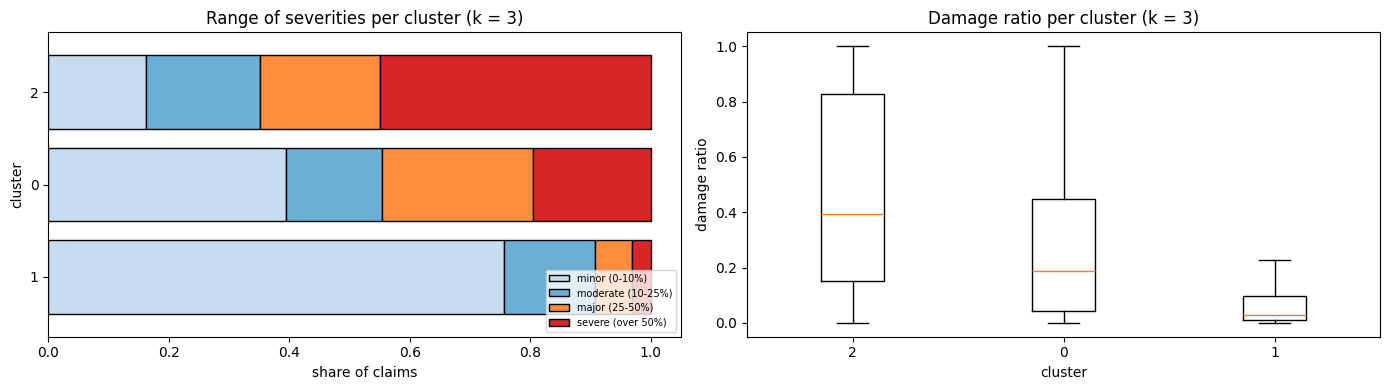

,foundation,zone,occupancy,claims_with_ratio,median_ratio,q75_ratio,minor (0-10%),moderate (10-25%),major (25-50%),severe (over 50%),major or severe
cluster,,,,,,,,,,,
2,elevated (4),AE,mobile home,381,0.393,0.826,0.163,0.189,0.199,0.449,0.648
0,slab,AE,single family,13368,0.189,0.447,0.394,0.159,0.251,0.195,0.447
1,elevated (6),AE,single family,1959,0.030,0.098,0.756,0.152,0.061,0.031,0.092


In [6]:
BANDS = ['minor (0-10%)', 'moderate (10-25%)', 'major (25-50%)', 'severe (over 50%)']
BAND_COLORS = ['#c6dbef', '#6baed6', '#fd8d3c', '#d62728']

def severity_profile(data, label_col):
    has_ratio = data['damage_ratio'].notna()
    shares = pd.crosstab(data.loc[has_ratio, label_col], data.loc[has_ratio, 'severity_band'], normalize='index').reindex(columns=BANDS)
    stats = data[has_ratio].groupby(label_col)['damage_ratio'].agg(claims_with_ratio='size', median_ratio='median',
                                                                  q75_ratio=lambda r: r.quantile(0.75))
    out = stats.join(shares)
    out['major or severe'] = out['major (25-50%)'] + out['severe (over 50%)']
    return out.sort_values('median_ratio', ascending=False)

def plot_severity(table, data, label_col, title):
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    table[BANDS].plot.barh(stacked=True, ax=ax[0], color=BAND_COLORS, edgecolor='black', width=0.8)
    ax[0].invert_yaxis(); ax[0].set_xlabel('share of claims'); ax[0].set_ylabel(label_col)
    ax[0].set_title(f'Range of severities per cluster ({title})'); ax[0].legend(fontsize=7, loc='lower right')
    order = list(table.index)
    ax[1].boxplot([data.loc[data[label_col] == c, 'damage_ratio'].dropna() for c in order], showfliers=False)
    ax[1].set_xticks(range(1, len(order) + 1), order); ax[1].set_xlabel(label_col); ax[1].set_ylabel('damage ratio')
    ax[1].set_title(f'Damage ratio per cluster ({title})')
    plt.tight_layout(); plt.show()

print('All claims in the sample:', d['severity_band'].value_counts(normalize=True).reindex(BANDS).round(3).to_dict())
sev3 = profile[['foundation', 'zone', 'occupancy']].join(severity_profile(d, 'cluster'), how='right')
plot_severity(sev3, d, 'cluster', 'k = 3')
sev3.round(3)

**How strong is the link?** We compare each grouping with the **severity band** using two scores that measure how much two
labellings agree:
- **NMI** (normalized mutual information): how much knowing the group tells us about the severity band. 0 = nothing, 1 = everything.
- **ARI** (adjusted Rand index): are pairs of claims in the same group exactly when they are in the same severity band?
  0 = no more than chance, 1 = perfect.

We look at them **side by side** for the clusters and for simpler groupings made from single columns.
The grouping with the higher score tells us more about the severity.

In [7]:
from sklearn.metrics import normalized_mutual_info_score

def agreement(groups, outcome):
    return {'NMI': normalized_mutual_info_score(outcome, groups), 'ARI': adjusted_rand_score(outcome, groups)}

k = d['severity_band'].notna()
band = d.loc[k, 'severity_band']
pd.DataFrame({
    'K-means clusters (k = 3)': agreement(d.loc[k, 'cluster'], band),
    'foundation alone': agreement(d.loc[k, 'foundation'], band),
    'flood zone alone': agreement(d.loc[k, 'zone'], band),
    'zone + foundation together': agreement(d.loc[k, 'zone'] + ' | ' + d.loc[k, 'foundation'], band)}).T.round(3)

,NMI,ARI
K-means clusters (k = 3),0.049,-0.021
foundation alone,0.078,-0.021
flood zone alone,0.016,-0.017
zone + foundation together,0.074,-0.005


**What we see with k = 3**
- In the whole sample, 43% of the claims are **minor** (under 10% of the building value), and 41% are **major or severe** (over 25%).
- The three clusters have very different ranges:
  - **Elevated homes** (cluster 1): 76% minor, only 9% major or severe, median damage ratio **3%**.
  - **Slab homes** (cluster 0, the big cluster): median **19%**, 45% major or severe.
  - **Mobile homes** (cluster 2): median **39%**, and 65% major or severe; almost half (45%) lost more than half of their value.
- **This changed our view of mobile homes.** With the yes/no high-severity flag (a dollar cut-off) they looked like the *safest* group (4%),
  only because their coverage is low ($70,000). Measured as a share of the building value, they are the **most damaged** group.
- **NMI is 0.049**: knowing the cluster tells us a little about the severity band. The foundation column **alone** tells us more (NMI 0.078),
  and zone + foundation together about the same (0.074). The flood zone alone tells us very little (0.016).
- **ARI is close to 0 for every grouping** (-0.02 to 0.00). ARI checks *pairs* of claims: are two claims in the same group exactly when they are
  in the same severity band? Our groups have many claims in every band, so this is almost never true. ARI is made for comparing **two clusterings**
  (like K-means vs hierarchical in section 3), so for the link with severity we use **NMI** and the band shares.

### 5.1 We also tried k = 7

With k = 3 one cluster has most of the claims, so the groups are very rough. In the silhouette table, k = 7 has the
next-best score among the larger k values. We know we chose it **after** looking, so we show it next to k = 3 and not instead of it.

Silhouette with k = 7: 0.223
Agreement of the 7 clusters with the severity band: {'NMI': 0.069, 'ARI': 0.017}


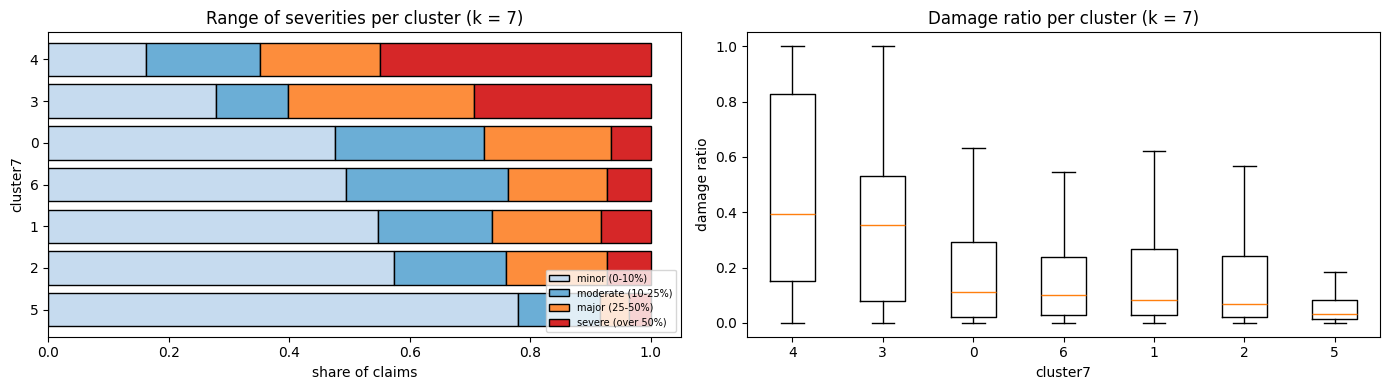

,claims,foundation,foundation_share,zone,occupancy,median_age,median_coverage,florida_share,claims_with_ratio,median_ratio,q75_ratio,minor (0-10%),moderate (10-25%),major (25-50%),severe (over 50%),major or severe
cluster7,,,,,,,,,,,,,,,,
4,491,elevated (4),0.54,AE,mobile home,41.85,70000.0,0.72,381,0.39,0.83,0.16,0.19,0.20,0.45,0.65
3,9040,slab,0.76,AE,single family,52.71,250000.0,0.73,7196,0.35,0.53,0.28,0.12,0.31,0.29,0.60
0,313,slab,0.66,AE,5+ units,50.31,500000.0,0.45,256,0.11,0.29,0.48,0.25,0.21,0.07,0.28
6,1447,slab,0.78,AE,non-residential,48.45,390000.0,0.43,1099,0.10,0.24,0.49,0.27,0.16,0.07,0.24
1,2778,slab,0.65,X,single family,43.74,250000.0,0.25,2060,0.08,0.27,0.55,0.19,0.18,0.08,0.26
2,4534,slab,0.47,AE,single family,45.74,250000.0,0.56,3540,0.07,0.24,0.57,0.19,0.17,0.07,0.24
5,1397,elevated (5),1.00,AE,single family,33.74,250000.0,0.61,1176,0.03,0.08,0.78,0.14,0.05,0.04,0.09


In [8]:
km7 = KMeans(n_clusters=7, n_init=10, random_state=SEED).fit(Xs)
d['cluster7'] = km7.labels_
t7 = d.groupby('cluster7').agg(claims=('id', 'size'), foundation=('foundation', most_common),
                               foundation_share=('foundation', share_most_common), zone=('zone', most_common),
                               occupancy=('occupancy', most_common), median_age=('building_age', 'median'),
                               median_coverage=('totalBuildingInsuranceCoverage', 'median'),
                               florida_share=('state', lambda s: (s == 'FL').mean()))
t7['foundation'] = t7['foundation'].map(FOUNDATION_NAMES)
t7['occupancy'] = t7['occupancy'].map(OCCUPANCY_NAMES).fillna(t7['occupancy'])
sev7 = t7.join(severity_profile(d, 'cluster7'), how='right')
print(f"Silhouette with k = 7: {silhouette_score(Xs, km7.labels_, sample_size=5000, random_state=SEED):.3f}")
print('Agreement of the 7 clusters with the severity band:', {n: round(v, 3) for n, v in agreement(d.loc[k, 'cluster7'], band).items()})
plot_severity(sev7, d, 'cluster7', 'k = 7')
sev7.round(2)

**What we see with k = 7** (ordered from the most to the least damaged)

| Cluster profile | Claims | Median damage ratio | Major or severe (over 25%) |
|---|---|---|---|
| mobile homes (coverage $70,000) | 491 | **39%** | **65%** |
| slab, single family, zone AE (73% Florida) | 9,040 | **35%** | **60%** |
| slab, 5+ unit buildings, zone AE | 313 | 11% | 28% |
| slab, non-residential, zone AE | 1,447 | 10% | 24% |
| slab, single family, zone X | 2,778 | 8% | 26% |
| slab, single family, mixed zones | 4,534 | 7% | 24% |
| elevated single-family homes | 1,397 | **3%** | **9%** |

- **The range of severities is very different between the clusters**, even though damage was never used to make them.
  The most damaged groups lose a median of 35-39% of their value; elevated homes only 3%.
- **Big buildings are not the most damaged.** With the dollar cut-off, the 5+ unit and non-residential buildings looked the riskiest (48% and 29%
  "high severity"). As a share of their value they lose only 10-11%: they cross the dollar line because they are **big**, not because they are
  badly damaged.
- **NMI is 0.069**, more than with k = 3 (0.049) but still a little **below the foundation column alone (0.078)**. ARI is about 0 (0.017).
- So the clusters show real risk profiles, but the main thing they find is the **foundation** (slab or elevated), the **flood zone** and
  whether it is a **mobile home**.

## 6. PCA: does a smaller version of the data give better clusters?

PCA makes new columns (components) that keep as much of the variation as possible. We keep enough components for **80% of the variance**,
then run K-means again with the same k.

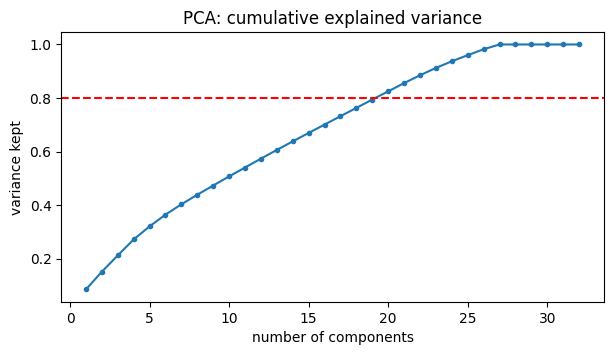

Components for 80% of the variance: 20 of 32
PC1 explains 8.5%, PC2 explains 6.6%


Silhouette, K-means on all columns : 0.256


Silhouette, K-means on PCA         : 0.254
Agreement between the two (ARI)    : 0.081


In [9]:
pca = PCA(random_state=SEED).fit(Xs)
cum = np.cumsum(pca.explained_variance_ratio_)
n_keep = int(np.argmax(cum >= 0.80) + 1)
plt.figure(figsize=(7, 3.5)); plt.plot(range(1, len(cum) + 1), cum, marker='.'); plt.axhline(0.8, color='red', ls='--')
plt.xlabel('number of components'); plt.ylabel('variance kept'); plt.title('PCA: cumulative explained variance'); plt.show()
Z = pca.transform(Xs)[:, :n_keep]
km_pca = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(Z)
print(f'Components for 80% of the variance: {n_keep} of {Xs.shape[1]}')
print(f'PC1 explains {pca.explained_variance_ratio_[0]:.1%}, PC2 explains {pca.explained_variance_ratio_[1]:.1%}')
print(f'Silhouette, K-means on all columns : {silhouette_score(Xs, kmeans.labels_, sample_size=5000, random_state=SEED):.3f}')
print(f'Silhouette, K-means on PCA         : {silhouette_score(Z, km_pca.labels_, sample_size=5000, random_state=SEED):.3f}')
print(f'Agreement between the two (ARI)    : {adjusted_rand_score(kmeans.labels_, km_pca.labels_):.3f}')

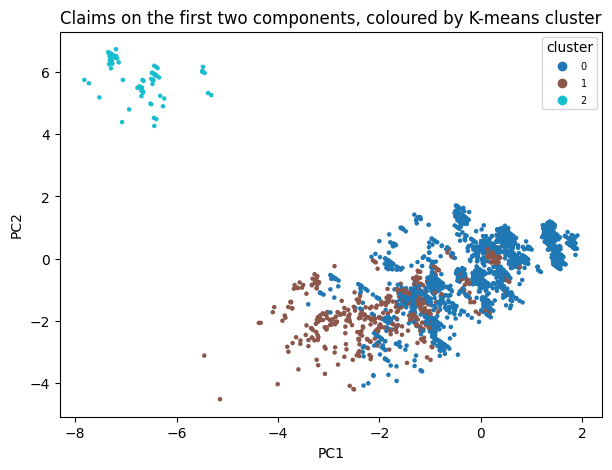

In [10]:
P = pca.transform(Xs)[:, :2]
s = np.random.default_rng(SEED).choice(len(P), 5000, replace=False)
plt.figure(figsize=(7, 5))
sc = plt.scatter(P[s, 0], P[s, 1], c=d['cluster'].values[s], cmap='tab10', s=5)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('Claims on the first two components, coloured by K-means cluster')
plt.legend(*sc.legend_elements(), title='cluster', fontsize=7, bbox_to_anchor=(1, 1)); plt.show()

**What we see.** PCA needs **20 of 32** components to keep 80% of the variance; the first component explains only 8.5%.
The silhouette on PCA is the same as before (0.25 vs 0.26), but the groups are very different (ARI 0.08).
So PCA did **not** give better clusters, and the new groups are harder to explain because each component mixes many columns.
In the scatter plot the clusters overlap, which matches the low silhouette.

## 7. DBSCAN: a different kind of clustering

K-means needs the number of clusters *k*, and it puts **every** claim into a cluster. **DBSCAN** works in another way:
it looks for **dense areas**, where many claims are close to each other.

- `eps`: the radius of the "neighbourhood" around a claim.
- `min_samples`: how many claims must be inside that radius to call it a dense area.
- A claim with at least `min_samples` neighbours is a **core** point. Core points that are close to each other form one cluster.
- A claim that is near a core point but has fewer neighbours itself is a **border** point (it joins that cluster).
- A claim that is not near any core point is **noise** (label -1). It belongs to no cluster.

So DBSCAN finds the number of clusters **by itself**, can find clusters of any shape, and can say "this claim fits nowhere".

**How we choose `eps`.** We use `min_samples = 20`. For every claim we measure the distance to its 20th nearest neighbour,
sort these distances and plot them (the **k-distance plot**). Where the curve bends upwards, distances jump from "inside a dense area"
to "outside". We try three values of `eps` from this curve (the 50%, 75% and 90% points) and compare the results.
DBSCAN is slow, so we use 5,000 of the 20,000 claims (the same 5,000 as for hierarchical clustering).

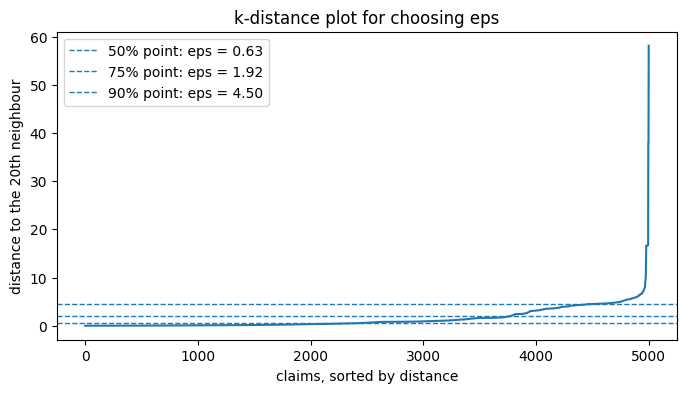

In [11]:
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN

MIN_SAMPLES = 20
Xd = Xs[sub]
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Xd)
dist, _ = nn.kneighbors(Xd)
k_dist = np.sort(dist[:, -1])
eps_values = {'50%': np.percentile(k_dist, 50), '75%': np.percentile(k_dist, 75), '90%': np.percentile(k_dist, 90)}

plt.figure(figsize=(8, 4))
plt.plot(k_dist)
for name, e in eps_values.items():
    plt.axhline(e, ls='--', lw=1, label=f'{name} point: eps = {e:.2f}')
plt.xlabel('claims, sorted by distance'); plt.ylabel(f'distance to the {MIN_SAMPLES}th neighbour')
plt.title('k-distance plot for choosing eps'); plt.legend(); plt.show()

In [12]:
rows = []
db_labels = {}
for name, e in eps_values.items():
    lab = DBSCAN(eps=e, min_samples=MIN_SAMPLES).fit(Xd).labels_
    db_labels[name] = lab
    in_cluster = lab >= 0
    n_clusters = len(set(lab[in_cluster]))
    sil = silhouette_score(Xd[in_cluster], lab[in_cluster]) if n_clusters > 1 else np.nan
    sizes = pd.Series(lab[in_cluster]).value_counts()
    rows.append({'eps from': name, 'eps': round(e, 2), 'clusters': n_clusters, 'noise share': (lab == -1).mean(),
                 'largest cluster': sizes.max() if len(sizes) else 0, 'clusters under 50 claims': int((sizes < 50).sum()),
                 'silhouette (noise left out)': sil,
                 'ARI with K-means (k=7)': adjusted_rand_score(km7.labels_[sub][in_cluster], lab[in_cluster])})
db_table = pd.DataFrame(rows).set_index('eps from')
db_table.round(3)

,eps,clusters,noise share,largest cluster,clusters under 50 claims,silhouette (noise left out),ARI with K-means (k=7)
eps from,,,,,,,
50%,0.63,24,0.458,1139,12,0.543,0.436
75%,1.92,31,0.214,1490,10,0.614,0.501
90%,4.50,15,0.057,3411,4,0.319,0.086


We look closer at the DBSCAN result with `eps` from the **90% point**, because it labels the fewest claims as noise.
Do its clusters have a different range of severities, like the K-means clusters?

In [13]:
lab = db_labels['90%']
dsub = d.iloc[sub].copy()
dsub['dbscan'] = lab
db_profile = dsub[dsub['dbscan'] >= 0].groupby('dbscan').agg(
    claims=('id', 'size'), foundation=('foundation', most_common), foundation_share=('foundation', share_most_common),
    zone=('zone', most_common), zone_share=('zone', share_most_common), occupancy=('occupancy', most_common))
db_profile['foundation'] = db_profile['foundation'].map(FOUNDATION_NAMES)
db_profile['occupancy'] = db_profile['occupancy'].map(OCCUPANCY_NAMES).fillna(db_profile['occupancy'])
db_sev = db_profile.join(severity_profile(dsub[dsub['dbscan'] >= 0], 'dbscan')[['median_ratio', 'major or severe']])
noise = dsub[dsub['dbscan'] == -1]
print(f"Noise claims: {len(noise):,} of {len(lab):,}  -  median damage ratio {noise['damage_ratio'].median():.2f},"
      f" major or severe {noise['severity_band'].isin(BANDS[2:]).sum() / noise['severity_band'].notna().sum():.1%}")
print(f"All 5,000 claims  -  median damage ratio {dsub['damage_ratio'].median():.2f},"
      f" major or severe {dsub['severity_band'].isin(BANDS[2:]).sum() / dsub['severity_band'].notna().sum():.1%}")
kb = dsub['severity_band'].notna() & (dsub['dbscan'] >= 0)
kf = dsub['severity_band'].notna()
print('Agreement of the DBSCAN clusters with the severity band:', {n: round(v, 3) for n, v in agreement(dsub.loc[kb, 'dbscan'], dsub.loc[kb, 'severity_band']).items()})
print('For comparison, foundation alone on the same 5,000 claims:', {n: round(v, 3) for n, v in agreement(dsub.loc[kf, 'foundation'], dsub.loc[kf, 'severity_band']).items()})
print('\nThe 10 biggest DBSCAN clusters:')
db_sev.sort_values('claims', ascending=False).head(10).round(2)

Noise claims: 285 of 5,000  -  median damage ratio 0.05, major or severe 21.2%
All 5,000 claims  -  median damage ratio 0.16, major or severe 41.3%
Agreement of the DBSCAN clusters with the severity band: {'NMI': 0.035, 'ARI': -0.016}
For comparison, foundation alone on the same 5,000 claims: {'NMI': 0.085, 'ARI': -0.015}

The 10 biggest DBSCAN clusters:


,claims,foundation,foundation_share,zone,zone_share,occupancy,median_ratio,major or severe
dbscan,,,,,,,,
0,3411,slab,0.71,AE,0.81,single family,0.21,0.46
8,216,elevated (6),1.00,AE,0.89,single family,0.04,0.08
9,167,slab,0.74,AE,0.95,condo building,0.30,0.53
1,163,slab,0.54,AE,0.82,2-4 units,0.19,0.41
4,114,slab,0.39,V,1.00,single family,0.12,0.36
3,112,slab,0.62,A,1.00,single family,0.16,0.36
14,107,slab,0.87,AE,0.85,unit in building,0.02,0.14
6,102,elevated (4),0.58,AE,0.92,mobile home,0.31,0.59
10,84,basement,0.32,AE,0.75,single family,0.05,0.07


**What we see**
- **The result depends a lot on `eps`.** With a small `eps` (50% point) DBSCAN finds 24 clusters but calls **46%** of the claims noise.
  With the 75% point it finds 31 clusters and 21% noise. With the 90% point it finds 15 clusters and only 5.7% noise.
- **The highest silhouette (0.61 at the 75% point) is misleading.** Many of those clusters are tiny (10 have under 50 claims): they are
  small groups of claims with exactly the same codes (same zone, foundation, floors, occupancy). They are very "tight", so the silhouette is high,
  but they are too small and too many to be useful risk profiles.
- **With the 90% point, one cluster has 68% of the claims** (3,411 of 5,000: slab, single family, zone AE, median damage ratio 21%).
  The small clusters show the same pattern as K-means: **mobile homes** (median 31%, 59% major or severe) and **condo buildings on slab in
  zone AE** (median 30%) are badly damaged; **elevated homes** (4%) and **units inside a building** (2%) are not.
- **NMI is 0.035**, clearly below the foundation column alone on the same 5,000 claims (0.085). ARI is about 0 (-0.016).
- The 285 noise claims are **less** damaged than average (median damage ratio 5% vs 16% for all 5,000 claims).

**Our conclusion on DBSCAN.** DBSCAN does not find clearly separated dense groups either. Our claims are not "islands" of points with empty
space between them: they are one big cloud plus many small groups with identical codes. DBSCAN confirms the same risk pattern as K-means,
but it does not give a better or clearer answer.

## 8. Our answer to RQ3

| Clustering | Silhouette | NMI with severity band | Range of severities (median damage ratio), most to least damaged cluster |
|---|---|---|---|
| K-means, k = 3 (our rule) | 0.26 | 0.049 | 39% → 3% |
| K-means, k = 7 | 0.22 | 0.069 | 39% → 3% |
| Hierarchical, k = 3 | 0.26 | - | (agrees with K-means only a little, ARI 0.22) |
| K-means on PCA (20 components) | 0.25 | - | (very different groups, ARI 0.08) |
| DBSCAN, eps from the 90% point (5,000 claims) | 0.32 (noise left out) | 0.035 | 31% → 2%; one cluster has 68% of the claims, 5.7% noise |
| *foundation column alone (no clustering)* | - | *0.078* | - |

> **Partly.** The claims do not form clear, separate groups: the silhouette is low (0.22-0.26), different methods find different groups,
> and DBSCAN finds one big cloud plus many small groups made of identical codes.
> But the groups have a very different **range of severities**, although damage was never used to make them. Measured as a share of the
> building value, **mobile homes** (median 39%, 65% major or severe) and **slab single-family homes in zone AE** (median 35%, 60%) are the most
> damaged, and **elevated homes** the least (median 3%, 9%). Big buildings (5+ units, businesses) lose only about 10% of their value.
> The foundation column alone tells us more about the severity than any of the clusterings (NMI 0.078 vs 0.035-0.069).

**What we learned**
- **How we measure severity changes the answer.** With a dollar cut-off ("top 20% of damage"), big buildings looked the riskiest and mobile homes
  the safest. With the damage ratio it is the other way round. The dollar cut-off mostly measures **building size**; the damage ratio measures
  **how badly the building was hit**.
- Clustering helped us **see** the risk profiles, but the strongest information is already in one column (foundation).
  One-hot columns dominate the distances, so the clusters mostly follow the foundation and occupancy codes.
- "Similar flood risk" here means a similar range of damage **once a flood claim happened**. Our data has only claims, so we cannot say how
  *likely* each building is to flood.